# Tarea

**Tema:** distribuciones especiales de probabilidad (binomial, Poisson, hipergeométrica, uniforme, gamma, χ² y t de Student)

**Estudiante:** Isabella Barbosa Mahecha

**Profesor:** Carlos Lesmes

**Universidad:** Santo Tomás

**Código de estudiante:** 2451795

# Ejercicios a realizar

En el siguiente código Julia cambie `1234` por su código de estudiante y corra la celda. Con el resultado, realice los ejercicios del capítulo 4 de Serie Schaum en este mismo archivo. Escriba los enunciados y *todos* los procedimientos para resolver cada ejercicio. Si es necesario haga las gráficas adecuadas y use los paquetes de Julia que necesite para esto. Guarde este archivo ipynb en su cuenta de github y envíe la dirección al enlace Moodle de esta tarea.

![Schaum](prob.png)

In [30]:
using Random, Distributions
Random.seed!(2451795)


TaskLocalRNG()

In [31]:
sort!(sample([61:94; 98:104; 108:120],15,replace=false,ordered=false))


15-element Vector{Int64}:
  61
  65
  74
  77
  78
  79
  86
  87
  91
  98
 103
 108
 110
 116
 119

En este caso debe resolver los ejercicios `4.70`, `4.71`, ..., `4.120`.

## Selección de ejercicios

Con el código 2451795 se sembró el generador de Julia y la muestra salió con 15 ejercicios: 61, 65, 74, 77, 78, 79, 86, 87, 91, 98, 103, 108, 110, 116 y 119.

In [32]:
using Plots, Statistics

## Ejercicios

Cada ejercicio tiene el enunciado, el procedimiento, una celda de Julia que hace el cálculo y, cuando aporta algo, una gráfica.

### 4.61 · Caras al lanzar una moneda seis veces

**Enunciado.** Encuentre la probabilidad de que al lanzar una moneda justa 6 veces aparezcan (a) 0, (b) 1, (c) 2, (d) 3, (e) 4, (f) 5 y (g) 6 caras.

**Procedimiento.** Sea $X$ el número de caras en 6 lanzamientos independientes con $p = 1/2$. Entonces $X \sim \text{Binomial}(6, 1/2)$ y

$$P(X = k) = \binom{6}{k}\left(\tfrac{1}{2}\right)^{6} = \frac{\binom{6}{k}}{64}, \qquad k = 0, 1, \dots, 6$$

Como la moneda es justa, $P(X=k) = P(X=6-k)$. Eso sirve para revisar el resultado: (e) debe dar lo mismo que (c), (f) lo mismo que (b) y (g) lo mismo que (a).

In [33]:
d = Binomial(6, 1/2)

for k in 0:6
    println("P(X = $k) = ", binomial(6, k) // 64, "  ≈ ", round(pdf(d, k), digits=5))
end

P(X = 0) = 1//64  ≈ 0.01562
P(X = 1) = 3//32  ≈ 0.09375
P(X = 2) = 15//64  ≈ 0.23437
P(X = 3) = 5//16  ≈ 0.3125
P(X = 4) = 15//64  ≈ 0.23437
P(X = 5) = 3//32  ≈ 0.09375
P(X = 6) = 1//64  ≈ 0.01562


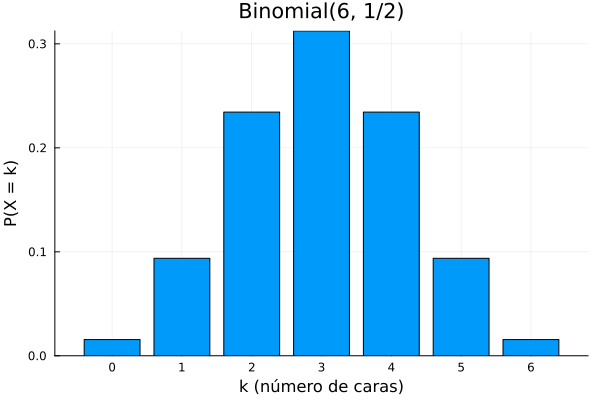

In [34]:
bar(0:6, pdf.(d, 0:6), legend=false,
    xlabel="k (número de caras)", ylabel="P(X = k)",
    title="Binomial(6, 1/2)")

**Respuesta.** (a) 1/64 ≈ 0.0156; (b) 3/32 ≈ 0.0938; (c) 15/64 ≈ 0.2344; (d) 5/16 = 0.3125; (e) 15/64 ≈ 0.2344; (f) 3/32 ≈ 0.0938; (g) 1/64 ≈ 0.0156.

### 4.65 · Suma de 11 con dos dados

**Enunciado.** Encuentre la probabilidad de obtener una suma de 11 (a) una vez y (b) dos veces, en dos lanzamientos de un par de dados justos.

**Procedimiento.** Hay 36 resultados posibles para el par de dados y solo dos suman 11: (5, 6) y (6, 5). Entonces la probabilidad de sacar 11 en un lanzamiento es

$$p = \frac{2}{36} = \frac{1}{18}$$

Los dos lanzamientos son independientes, así que el número de veces $Y$ que sale 11 sigue una $\text{Binomial}(2, 1/18)$:

- (a) $P(Y = 1) = 2\,p\,(1-p) = 2 \cdot \frac{1}{18} \cdot \frac{17}{18} = \frac{17}{162}$
- (b) $P(Y = 2) = p^2 = \frac{1}{324}$

In [35]:
resultados = [(i, j) for i in 1:6, j in 1:6]
favorables = count(r -> r[1] + r[2] == 11, resultados)
p = favorables // 36                       
println("Casos favorables: ", favorables, "   p = ", p)

Y = Binomial(2, Float64(p))
println("(a) una vez:   ", 2p * (1 - p), "  ≈ ", round(pdf(Y, 1), digits=5))
println("(b) dos veces: ", p^2, "  ≈ ", round(pdf(Y, 2), digits=6))

Casos favorables: 2   p = 1//18
(a) una vez:   17//162  ≈ 0.10494
(b) dos veces: 1//324  ≈ 0.003086


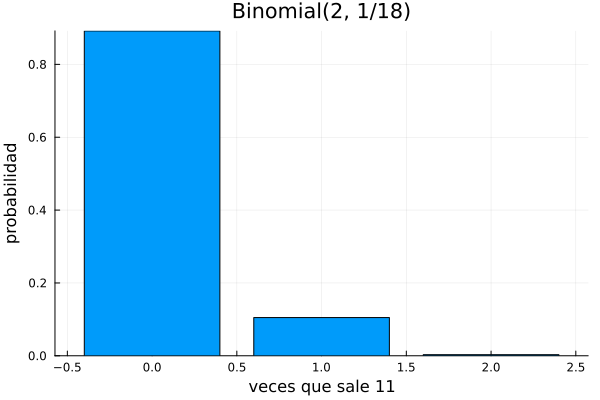

In [36]:
bar(0:2, pdf.(Y, 0:2), legend=false,
    xlabel="veces que sale 11", ylabel="probabilidad",
    title="Binomial(2, 1/18)")

**Respuesta.** (a) 17/162 ≈ 0.1049; (b) 1/324 ≈ 0.0031.

### 4.74 · Área bajo la normal estándar entre dos valores

**Enunciado.** Encuentre el área bajo la curva normal estándar entre (a) $z = -1.20$ y $z = 2.40$, (b) $z = 1.23$ y $z = 1.87$, (c) $z = -2.35$ y $z = -0.50$.

**Procedimiento.** Con $Z \sim N(0, 1)$ y $\Phi$ su función de distribución acumulada, el área entre $a$ y $b$ es

$$P(a \le Z \le b) = \Phi(b) - \Phi(a)$$

En Julia, $\Phi$ es `cdf(Z, z)`.

In [37]:
Z = Normal(0, 1)

area_a = cdf(Z, 2.40) - cdf(Z, -1.20)
area_b = cdf(Z, 1.87) - cdf(Z, 1.23)
area_c = cdf(Z, -0.50) - cdf(Z, -2.35)

println("(a) ", round(area_a, digits=4))
println("(b) ", round(area_b, digits=4))
println("(c) ", round(area_c, digits=4))

(a) 0.8767
(b) 0.0786
(c) 0.2992


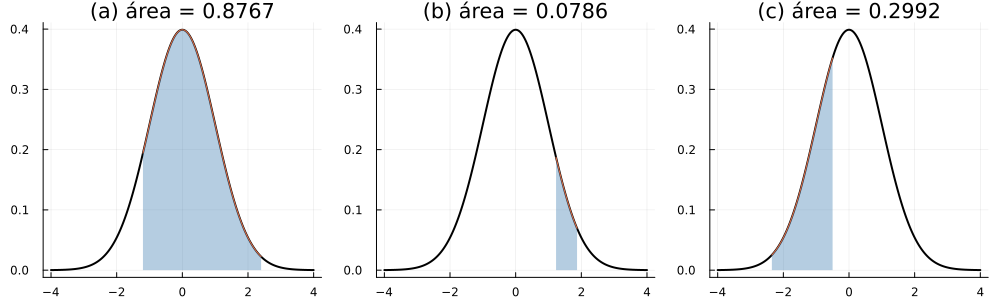

In [38]:
function sombrear_normal(a, b, etiqueta)
    xs = range(-4, 4, length=400)
    p = plot(xs, pdf.(Z, xs), color=:black, lw=2, legend=false, title=etiqueta)
    xr = range(a, b, length=200)
    plot!(p, xr, pdf.(Z, xr), fill=(0, 0.4, :steelblue))
    return p
end

p1 = sombrear_normal(-1.20, 2.40, "(a) área = $(round(area_a, digits=4))")
p2 = sombrear_normal(1.23, 1.87, "(b) área = $(round(area_b, digits=4))")
p3 = sombrear_normal(-2.35, -0.50, "(c) área = $(round(area_c, digits=4))")
plot(p1, p2, p3, layout=(1, 3), size=(1000, 300))

**Respuesta.** (a) 0.8767; (b) 0.0786; (c) 0.2992.

### 4.77 · Encontrar z a partir del área

**Enunciado.** Encuentre los valores de $z$ tales que (a) el área a la derecha de $z$ sea 0.2266; (b) el área a la izquierda de $z$ sea 0.0314; (c) el área entre $-0.23$ y $z$ sea 0.5722; (d) el área entre $1.15$ y $z$ sea 0.0730; (e) el área entre $-z$ y $z$ sea 0.9000.

**Procedimiento.** Aquí el camino es al revés: dada un área, busco $z$. La función `quantile(Z, p)` da el $z$ que cumple $\Phi(z) = p$.

- (a) Área a la derecha 0.2266 significa $\Phi(z) = 1 - 0.2266 = 0.7734$.
- (b) $\Phi(z) = 0.0314$.
- (c) $\Phi(z) - \Phi(-0.23) = 0.5722$, entonces $\Phi(z) = 0.5722 + \Phi(-0.23)$. Hay una sola solución porque la probabilidad crece con $z$.
- (d) Aquí hay dos soluciones. Si $z$ queda a la derecha de 1.15, $\Phi(z) = \Phi(1.15) + 0.0730$. Si queda a la izquierda, $\Phi(z) = \Phi(1.15) - 0.0730$. Las dos sirven porque el área entre 1.15 y $z$ es igual en ambos casos.
- (e) El área entre $-z$ y $z$ es $2\Phi(z) - 1 = 0.9$, entonces $\Phi(z) = 0.95$.

In [39]:
z_a  = quantile(Z, 1 - 0.2266)
z_b  = quantile(Z, 0.0314)
z_c  = quantile(Z, 0.5722 + cdf(Z, -0.23))
z_d1 = quantile(Z, cdf(Z, 1.15) + 0.0730)   
z_d2 = quantile(Z, cdf(Z, 1.15) - 0.0730)   
z_e  = quantile(Z, 0.5 + 0.9 / 2)

println("(a) z = ", round(z_a, digits=3), "   área a la derecha = ", round(ccdf(Z, z_a), digits=4))
println("(b) z = ", round(z_b, digits=3), "   área a la izquierda = ", round(cdf(Z, z_b), digits=4))
println("(c) z = ", round(z_c, digits=3))
println("(d) z = ", round(z_d1, digits=3), "  o  z = ", round(z_d2, digits=3))
println("(e) z = ±", round(z_e, digits=3))

(a) z = 0.75   área a la derecha = 0.2266
(b) z = -1.861   área a la izquierda = 0.0314
(c) z = 2.08
(d) z = 1.625  o  z = 0.849
(e) z = ±1.645


**Respuesta.** (a) z = 0.75; (b) z = −1.86; (c) z = 2.08; (d) z = 1.625 o z = 0.849; (e) z = ±1.645.

### 4.78 · Valor de $z_1$ con $P(Z \ge z_1) = 0.84$

**Enunciado.** Encuentre $z_1$ si $P(Z \ge z_1) = 0.84$, con $Z \sim N(0, 1)$.

**Procedimiento.** $P(Z \ge z_1) = 1 - \Phi(z_1) = 0.84$, entonces $\Phi(z_1) = 0.16$ y $z_1 = \Phi^{-1}(0.16)$. Como 0.16 es menor que 0.5, $z_1$ es negativo.

In [40]:
z1 = quantile(Z, 0.16)
println("z1 = ", round(z1, digits=4))
println("Comprobación: P(Z ≥ z1) = ", round(ccdf(Z, z1), digits=4))

z1 = -0.9945
Comprobación: P(Z ≥ z1) = 0.84


**Respuesta.** $z_1 \approx -0.9945$.

### 4.79 · Probabilidad de una normal con media 5 y desviación 2

**Enunciado.** Si $X$ es normal con media 5 y desviación estándar 2, encuentre $P(X > 8)$.

**Procedimiento.** Estandarizo: $z = \dfrac{8 - 5}{2} = 1.5$. Entonces $P(X > 8) = P(Z > 1.5) = 1 - \Phi(1.5)$.

In [41]:
X = Normal(5, 2)
z = (8 - 5) / 2
println("z = ", z)
println("P(X > 8) = ", round(ccdf(X, 8), digits=4))
println("Con z:     ", round(ccdf(Z, z), digits=4))

z = 1.5
P(X > 8) = 0.0668
Con z:     0.0668


**Respuesta.** $P(X > 8) \approx 0.0668$.

### 4.86 · Aproximación normal a la binomial con 200 lanzamientos

**Enunciado.** Encuentre la probabilidad de que 200 lanzamientos de una moneda den (a) entre 80 y 120 caras inclusive, (b) menos de 90 caras, (c) menos de 85 o más de 115 caras, (d) exactamente 100 caras.

**Procedimiento.** $X \sim \text{Binomial}(200, 1/2)$ tiene media $\mu = np = 100$ y desviación $\sigma = \sqrt{npq} = \sqrt{50} \approx 7.071$. Como $n$ es grande, aproximo con $Y \sim N(100, 7.071)$ usando la corrección por continuidad: un entero $k$ ocupa el intervalo $[k - 0.5,\ k + 0.5]$.

- (a) $P(80 \le X \le 120) \approx P(79.5 \le Y \le 120.5)$
- (b) $P(X < 90) = P(X \le 89) \approx P(Y \le 89.5)$
- (c) $P(X \le 84) + P(X \ge 116) \approx P(Y \le 84.5) + P(Y \ge 115.5)$
- (d) $P(X = 100) \approx P(99.5 \le Y \le 100.5)$

Como control calculo también la binomial exacta.

In [58]:
n, prob = 200, 1/2
μ = n * prob
σ = sqrt(n * prob * (1 - prob))
B = Binomial(n, prob)
Y = Normal(μ, σ)


aprox = [
    cdf(Y, 120.5) - cdf(Y, 79.5),       
    cdf(Y, 89.5),                        
    cdf(Y, 84.5) + ccdf(Y, 115.5),       
    cdf(Y, 100.5) - cdf(Y, 99.5),        
]


exacta = [
    cdf(B, 120) - cdf(B, 79),           
    cdf(B, 89),                         
    cdf(B, 84) + ccdf(B, 115),           
    pdf(B, 100),                         
]

println("Caso   Normal aprox.   Binomial exacta")
for (i, letra) in enumerate(["a", "b", "c", "d"])
    println(letra, "      ", round(aprox[i], digits=4), "         ", round(exacta[i], digits=4))
end

Caso   Normal aprox.   Binomial exacta
a      0.9963         0.9964
b      0.0688         0.0687
c      0.0284         0.0281
d      0.0564         0.0563


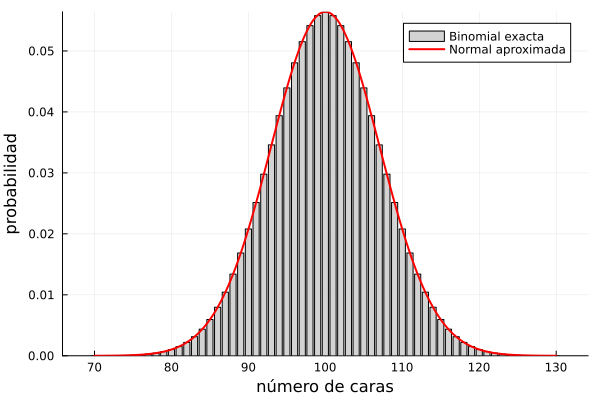

In [43]:
ks = 70:130
bar(ks, pdf.(B, ks), color=:lightgray, label="Binomial exacta",
    xlabel="número de caras", ylabel="probabilidad")
plot!(70:0.1:130, pdf.(Y, 70:0.1:130), lw=2, color=:red, label="Normal aproximada")

**Respuesta.**

| Caso | Normal con corrección | Binomial exacta | Libro |
|:--:|:--:|:--:|:--:|
| (a) | 0.9963 | 0.9964 | 0.9962 |
| (b) | 0.0688 | 0.0687 | 0.0687 |
| (c) | 0.0284 | 0.0281 | 0.0286 |
| (d) | 0.0564 | 0.0563 | 0.0558 |




### 4.87 · Adivinar respuestas de verdadero o falso

**Enunciado.** Encuentre la probabilidad de que un estudiante adivine correctamente (a) 12 o más de 20 preguntas, (b) 24 o más de 40 preguntas de verdadero o falso.

**Procedimiento.** Adivinar cada pregunta es un ensayo con $p = 1/2$, así que $X \sim \text{Binomial}(n, 1/2)$. Para $n$ grande uso $Y \sim N(n/2,\ \sqrt{n/4})$ con corrección por continuidad:

- (a) $n = 20$: $\mu = 10$, $\sigma = \sqrt{5}$, y $P(X \ge 12) \approx P(Y \ge 11.5)$
- (b) $n = 40$: $\mu = 20$, $\sigma = \sqrt{10}$, y $P(X \ge 24) \approx P(Y \ge 23.5)$

In [44]:
casos = [(20, 12), (40, 24)]         

for (n, k) in casos
    B = Binomial(n, 1/2)
    Y = Normal(n / 2, sqrt(n / 4))   # σ = √(n·p·q) = √(n/4)
    println("n = $n, P(X ≥ $k):  normal ≈ ", round(ccdf(Y, k - 0.5), digits=4),
            "   exacta = ", round(ccdf(B, k - 1), digits=4))
end

n = 20, P(X ≥ 12):  normal ≈ 0.2512   exacta = 0.2517
n = 40, P(X ≥ 24):  normal ≈ 0.1342   exacta = 0.1341


**Respuesta.** (a) ≈ 0.2512 (exacta 0.2517); (b) ≈ 0.1342 (exacta 0.1341). El libro trae 0.2511 y 0.1342.

### 4.91 · Bulbos defectuosos (Poisson)

**Enunciado.** En el problema 4.90, el 3% de los bulbos son defectuosos. En una muestra de 100 bulbos, encuentre la probabilidad de que (a) más de 5, (b) entre 1 y 3, (c) menos o igual a 2 sean defectuosos.

**Procedimiento.** Uso la aproximación de Poisson a la binomial con $\lambda = np = 100 \cdot 0.03 = 3$:

$$P(X = k) = \frac{e^{-3}\, 3^k}{k!}$$

Luego:

- (a) $P(X > 5) = 1 - P(X \le 5)$
- (b) $P(1 \le X \le 3) = P(X \le 3) - P(X \le 0)$
- (c) $P(X \le 2)$

Como control, calculo también la binomial exacta $\text{Binomial}(100, 0.03)$.

In [45]:
λ = 100 * 0.03
P = Poisson(λ)
B = Binomial(100, 0.03)

function comparar(letra, pois, bin)
    println("(", letra, ")  Poisson = ", round(pois, digits=4),
            "   Binomial exacta = ", round(bin, digits=4))
end

comparar("a", ccdf(P, 5), ccdf(B, 5))
comparar("b", cdf(P, 3) - cdf(P, 0), cdf(B, 3) - cdf(B, 0))
comparar("c", cdf(P, 2), cdf(B, 2))

(a)  Poisson = 0.0839   Binomial exacta = 0.0808
(b)  Poisson = 0.5974   Binomial exacta = 0.5997
(c)  Poisson = 0.4232   Binomial exacta = 0.4198


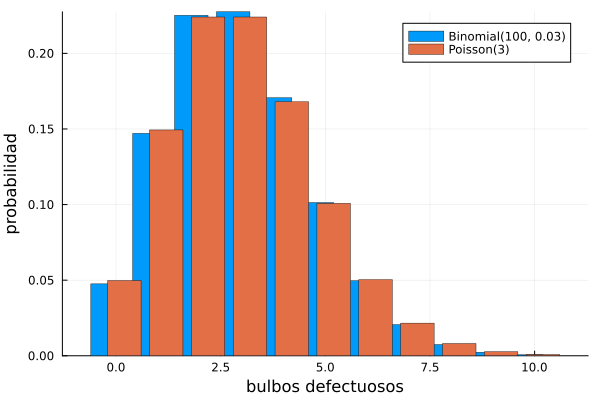

In [46]:
ks = 0:10
bar(ks .- 0.2, pdf.(B, ks), width=0.4, label="Binomial(100, 0.03)",
    xlabel="bulbos defectuosos", ylabel="probabilidad")
bar!(ks .+ 0.2, pdf.(P, ks), width=0.4, label="Poisson(3)")

**Respuesta.** Con Poisson: (a) 0.0839; (b) 0.5974; (c) 0.4232. Con la binomial exacta: 0.0808, 0.5997 y 0.4198. 

### 4.98 · Marbles sin reemplazo (hipergeométrica)

**Enunciado.** Una caja tiene 5 marbles rojas y 10 blancas. Si se escogen 8 al azar sin reemplazo, determine la probabilidad de que (a) 4 sean rojas, (b) todas sean blancas, (c) al menos una sea roja.

**Procedimiento.** Como las extracciones son sin reemplazo, $X$ (número de rojas) sigue una hipergeométrica con $N = 15$, $K = 5$ rojas y $n = 8$:

$$P(X = k) = \frac{\binom{5}{k}\binom{10}{8-k}}{\binom{15}{8}}, \qquad \binom{15}{8} = 6435$$

- (a) $\dfrac{\binom{5}{4}\binom{10}{4}}{6435} = \dfrac{5 \cdot 210}{6435} = \dfrac{70}{429}$
- (b) $\dfrac{\binom{10}{8}}{6435} = \dfrac{45}{6435} = \dfrac{1}{143}$
- (c) $1 - P(X = 0) = 1 - \dfrac{1}{143} = \dfrac{142}{143}$

In [47]:
H = Hypergeometric(5, 10, 8) 

println("(a) ", pdf(H, 4), "  = ", binomial(5, 4) * binomial(10, 4) // binomial(15, 8))
println("(b) ", pdf(H, 0), "  = ", binomial(10, 8) // binomial(15, 8))
println("(c) ", 1 - pdf(H, 0), "  = ", 142 // 143)

(a) 0.16317016317016328  = 70//429
(b) 0.0069930069930069895  = 1//143
(c) 0.993006993006993  = 142//143


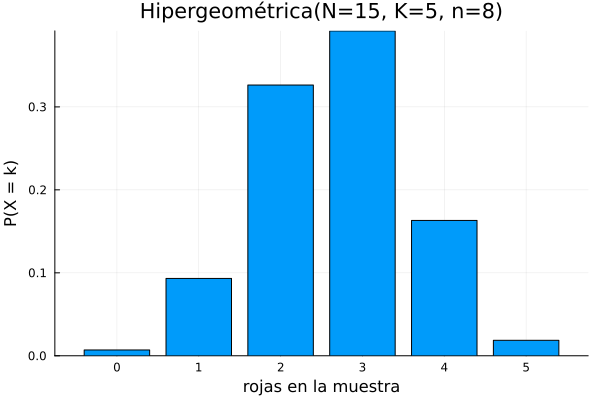

In [48]:
bar(0:5, pdf.(H, 0:5), legend=false,
    xlabel="rojas en la muestra", ylabel="P(X = k)",
    title="Hipergeométrica(N=15, K=5, n=8)")

**Respuesta.** (a) 70/429 ≈ 0.1632; (b) 1/143 ≈ 0.0070; (c) 142/143 ≈ 0.9930.

### 4.103 · Asimetría y curtosis de una uniforme

**Enunciado.** Determine el coeficiente de (a) asimetría y (b) curtosis de una distribución uniforme.

**Procedimiento.** Sea $X \sim U(a, b)$, con media $\mu = \frac{a+b}{2}$.

- (a) La distribución es simétrica alrededor de $\mu$, así que el momento central de orden 3 es 0 y el coeficiente de asimetría $\gamma_1 = 0$.
- (b) Para la curtosis, $\sigma^2 = \frac{(b-a)^2}{12}$ y $\mu_4 = \frac{(b-a)^4}{80}$. Entonces

$$\beta_2 = \frac{\mu_4}{\sigma^4} = \frac{(b-a)^4 / 80}{(b-a)^4 / 144} = \frac{9}{5}$$

El libro reporta $\beta_2 = 9/5$. La curtosis en exceso, que es la que entrega `kurtosis` en Distributions.jl, es $9/5 - 3 = -6/5$. El resultado no depende de $a$ ni de $b$.

In [49]:
d = Uniform(-1, 1)                  

println("Asimetría γ₁: ", skewness(d))
println("Curtosis en exceso: ", kurtosis(d), "   →  β₂ = ", kurtosis(d) + 3)
println("Valor racional de β₂: ", 9 // 5)

a, b = -1, 1
μ_num = (a + b) / 2
xs_num = range(a, b, length=1_000_001)
μ4 = mean((xs_num .- μ_num) .^ 4)    
σ2 = (b - a)^2 / 12
println("β₂ numérico = ", round(μ4 / σ2^2, digits=4))

Asimetría γ₁: 0.0
Curtosis en exceso: -1.2   →  β₂ = 1.8
Valor racional de β₂: 9//5
β₂ numérico = 1.8


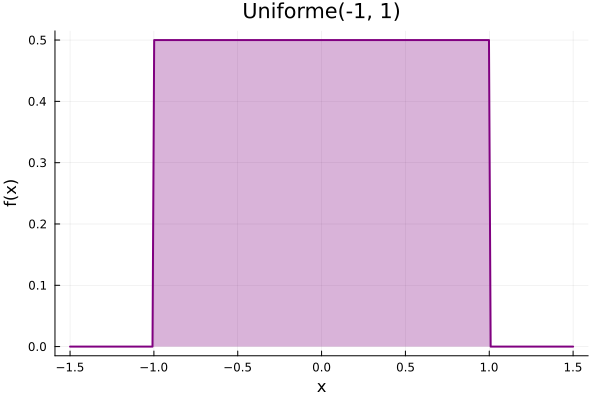

In [50]:
xp = range(-1.5, 1.5, length=300)
plot(xp, pdf.(d, xp), lw=2, color=:purple, fill=(0, 0.3, :purple),
     legend=false, title="Uniforme(-1, 1)", xlabel="x", ylabel="f(x)")

**Respuesta.** (a) $\gamma_1 = 0$; (b) $\beta_2 = 9/5$ (exceso de curtosis $-6/5$).

### 4.108 · Probabilidades de una gamma con α = 3 y β = 2

**Enunciado.** Una variable $X$ es gamma con $\alpha = 3$ y $\beta = 2$. Encuentre (a) $P(X \le 1)$, (b) $P(1 \le X \le 2)$.

**Procedimiento.** La densidad es $f(x) = \dfrac{x^{\alpha-1} e^{-x/\beta}}{\beta^\alpha\, \Gamma(\alpha)}$. Como $\alpha = 3$ es entero, la acumulada tiene forma cerrada:

$$P(X \le x) = 1 - e^{-x/\beta} \sum_{k=0}^{\alpha - 1} \frac{(x/\beta)^k}{k!}$$

- Para $x = 1$, $x/\beta = 1/2$: $P(X \le 1) = 1 - e^{-1/2}\left(1 + \tfrac{1}{2} + \tfrac{1}{8}\right) = 1 - \tfrac{13}{8}e^{-1/2}$.
- Para $x = 2$, $x/\beta = 1$: $P(X \le 2) = 1 - e^{-1}\left(1 + 1 + \tfrac{1}{2}\right) = 1 - \tfrac{5}{2}e^{-1}$.
- (b) $P(1 \le X \le 2) = P(X \le 2) - P(X \le 1)$.

En Julia, `Gamma(α, θ)` usa escala, así que la escala es $\beta = 2$.

In [51]:
G = Gamma(3, 2)                      

println("(a) P(X ≤ 1) = ", cdf(G, 1), "   forma cerrada: ", 1 - 13/8 * exp(-1/2))
println("(b) P(1 ≤ X ≤ 2) = ", cdf(G, 2) - cdf(G, 1),
        "   forma cerrada: ", 13/8 * exp(-1/2) - 5/2 * exp(-1))

(a) P(X ≤ 1) = 0.01438767796697069   forma cerrada: 0.014387677966970713
(b) P(1 ≤ X ≤ 2) = 0.06591371910442352   forma cerrada: 0.06591371910442345


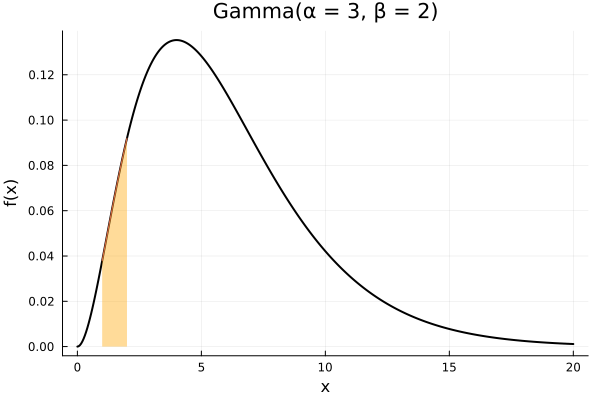

In [52]:
xs = range(0, 20, length=400)
p = plot(xs, pdf.(G, xs), lw=2, color=:black, legend=false,
         title="Gamma(α = 3, β = 2)", xlabel="x", ylabel="f(x)")
xr = range(1, 2, length=100)
plot!(p, xr, pdf.(G, xr), fill=(0, 0.4, :orange))

**Respuesta.** (a) $P(X \le 1) = 1 - \frac{13}{8}e^{-1/2} \approx 0.0144$; (b) $P(1 \le X \le 2) \approx 0.0659$.


### 4.110 · Valores de χ² con cola derecha de 0.05

**Enunciado.** Encuentre los valores de $\chi^2$ para los que el área de la cola derecha es 0.05, si los grados de libertad son (a) 8, (b) 19, (c) 28, (d) 40.

**Procedimiento.** $\chi^2_{0.05,\nu}$ es el valor que deja 0.05 a la derecha, es decir, el cuantil 0.95 de la distribución $\chi^2$ con $\nu$ grados de libertad. En Julia: `quantile(Chisq(ν), 0.95)`.

In [53]:
for (letra, ν) in zip(["a", "b", "c", "d"], [8, 19, 28, 40])
    crit = quantile(Chisq(ν), 0.95)
    println("(", letra, ")  ν = ", ν, "   χ² = ", round(crit, digits=4),
            "   cola derecha = ", round(ccdf(Chisq(ν), crit), digits=4))
end

(a)  ν = 8   χ² = 15.5073   cola derecha = 0.05
(b)  ν = 19   χ² = 30.1435   cola derecha = 0.05
(c)  ν = 28   χ² = 41.3371   cola derecha = 0.05
(d)  ν = 40   χ² = 55.7585   cola derecha = 0.05


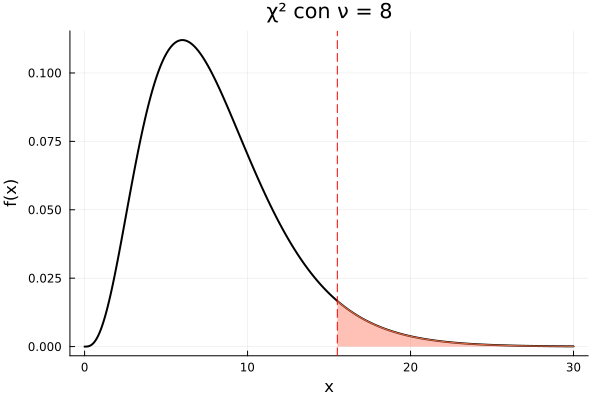

In [54]:
Q = Chisq(8)
c = quantile(Q, 0.95)
xs = range(0, 30, length=400)
p = plot(xs, pdf.(Q, xs), lw=2, color=:black, legend=false,
         title="χ² con ν = 8", xlabel="x", ylabel="f(x)")
xr = range(c, 30, length=200)
plot!(p, xr, pdf.(Q, xr), fill=(0, 0.4, :tomato))
vline!(p, [c], ls=:dash, color=:red)

**Respuesta.** (a) 15.51; (b) 30.14; (c) 41.34; (d) 55.76. El libro trae 15.5, 30.1, 41.3 y 55.8.

### 4.116 · Valores t con 15 grados de libertad

**Enunciado.** Para una t de Student con 15 grados de libertad, encuentre $t_1$ tal que (a) el área a la derecha de $t_1$ sea 0.01; (b) el área a la izquierda de $t_1$ sea 0.95; (c) el área a la derecha de $t_1$ sea 0.10; (d) el área combinada a la derecha de $t_1$ y a la izquierda de $-t_1$ sea 0.01; (e) el área entre $-t_1$ y $t_1$ sea 0.95.

**Procedimiento.** Uso `quantile(TDist(15), p)`, que da el valor con probabilidad $p$ a su izquierda:

- (a) $P(T \le t_1) = 0.99$
- (b) $p = 0.95$
- (c) $p = 0.90$
- (d) Son dos colas de 0.005 cada una, así que $p = 0.995$.
- (e) Las dos colas suman 0.05, así que $p = 0.975$.

In [55]:
T = TDist(15)

valores = [
    ("a", quantile(T, 0.99)),
    ("b", quantile(T, 0.95)),
    ("c", quantile(T, 0.90)),
    ("d", quantile(T, 0.995)),
    ("e", quantile(T, 0.975)),
]

for (letra, t) in valores
    println("(", letra, ")  t₁ = ", round(t, digits=4))
end

(a)  t₁ = 2.6025
(b)  t₁ = 1.7531
(c)  t₁ = 1.3406
(d)  t₁ = 2.9467
(e)  t₁ = 2.1314


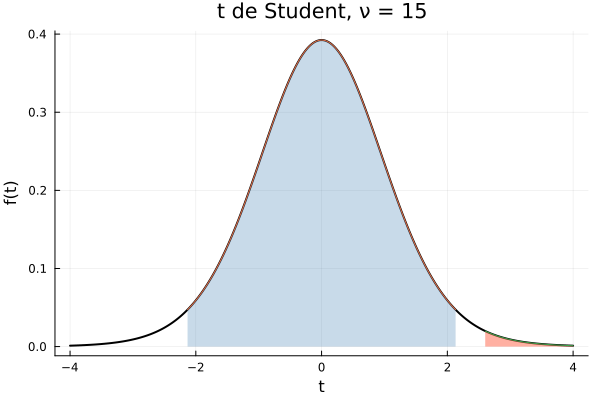

In [56]:
xs = range(-4, 4, length=400)
p = plot(xs, pdf.(T, xs), lw=2, color=:black, legend=false,
         title="t de Student, ν = 15", xlabel="t", ylabel="f(t)")
t_e = valores[5][2]
t_a = valores[1][2]
xc = range(-t_e, t_e, length=300)
plot!(p, xc, pdf.(T, xc), fill=(0, 0.3, :steelblue))
xr = range(t_a, 4, length=100)
plot!(p, xr, pdf.(T, xr), fill=(0, 0.5, :tomato))

**Respuesta.** (a) 2.60; (b) 1.75; (c) 1.34; (d) 2.95; (e) 2.13. 

### 4.119 · Constante c para una t con 10 grados de libertad

**Enunciado.** Si $U$ tiene distribución t de Student con $\nu = 10$, encuentre la constante $c$ tal que (a) $P(U > c) = 0.05$; (b) $P(-c \le U \le c) = 0.98$; (c) $P(U \le c) = 0.20$; (d) $P(U \ge c) = 0.90$.

**Procedimiento.**

- (a) $c = t_{0.95}$.
- (b) Si la probabilidad central es 0.98, cada cola es 0.01, así que $c = t_{0.99}$.
- (c) $c = t_{0.20}$. Como la probabilidad es menor que 0.5, $c$ es negativo.
- (d) $P(U \ge c) = 0.90$ equivale a $P(U < c) = 0.10$, así que $c = t_{0.10}$, también negativo.

In [57]:
U = TDist(10)

c_a = quantile(U, 0.95)
c_b = quantile(U, 0.99)
c_c = quantile(U, 0.20)
c_d = quantile(U, 0.10)

println("(a) c = ", round(c_a, digits=4), "   comprobación P(U > c) = ", round(ccdf(U, c_a), digits=4))
println("(b) c = ", round(c_b, digits=4), "   comprobación P(-c ≤ U ≤ c) = ", round(cdf(U, c_b) - cdf(U, -c_b), digits=4))
println("(c) c = ", round(c_c, digits=4), "   comprobación P(U ≤ c) = ", round(cdf(U, c_c), digits=4))
println("(d) c = ", round(c_d, digits=4), "   comprobación P(U ≥ c) = ", round(1 - cdf(U, c_d), digits=4))

(a) c = 1.8125   comprobación P(U > c) = 0.05
(b) c = 2.7638   comprobación P(-c ≤ U ≤ c) = 0.98
(c) c = -0.8791   comprobación P(U ≤ c) = 0.2
(d) c = -1.3722   comprobación P(U ≥ c) = 0.9


**Respuesta.** (a) c ≈ 1.8125; (b) c ≈ 2.7638; (c) c ≈ −0.8791; (d) c ≈ −1.3722. Por la forma de la condición, ambos valores tienen que ser negativos.